# Simple aerodynamic analysis

This notebook contains a simple set of aerodynamic analysis done on some airfoils done using neuralfoil (via the aerosandbox wrapper). Some further analysis tools (Principal Orthogonal Decomposition, FPCA) are tested later on. The goal is simply to illustrate what kind of field analysis can be done using Aerosandbox. 

Operating conditions used: 
- Angle of attack $\alpha$ 0 when nominal, -20, 20 for sweeps
- Reynolds 1e6 when nominal,  += 1e6 for sweeps (+ a small epsilon to avoid 0)

Model used: Neuralfoil (via aerosandbox) with `model_size` parameter set at `xxx_large` 

In [5]:
import aerosandbox as asb
import numpy as np 
from matplotlib import pyplot as plt 

In [7]:
# generate airfoil 
airfoil = asb.Airfoil("NACA0006")
# airfoil.draw(backend="matplotlib")

# generate aerodynamimc fields 
_grid_res = 100
alpha = 0
reynold = 1.5e6
re_variation = 1e6 - 1e-4 ## upper and lower variation considered for reynolds 
alphas = np.linspace(-20, 20, _grid_res)
reynolds = np.linspace(reynold - re_variation, reynold + re_variation, _grid_res)

## for field 
a_batch, re_batch = np.meshgrid(alphas, reynolds)

## different sweeps 
alpha_sweep = airfoil.get_aero_from_neuralfoil(alpha=alphas, Re=reynold, model_size="xxxlarge")
re_sweep = airfoil.get_aero_from_neuralfoil(alpha=alpha, Re=reynold, model_size='xxxlarge')

## aerodynamic field 
aero_fields = airfoil.get_aero_from_neuralfoil(alpha=a_batch.flatten(), Re=re_batch.flatten(), model_size="xxxlarge")

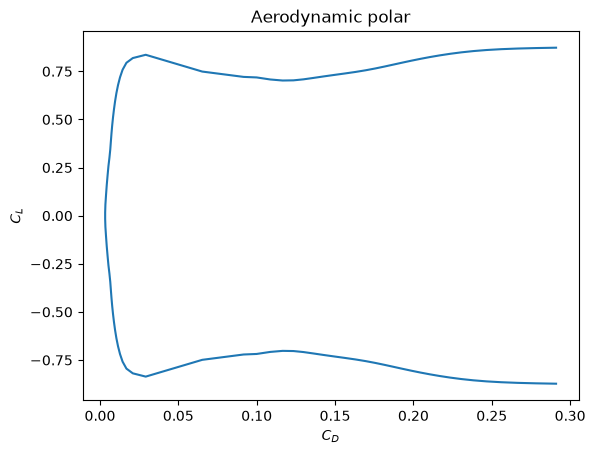

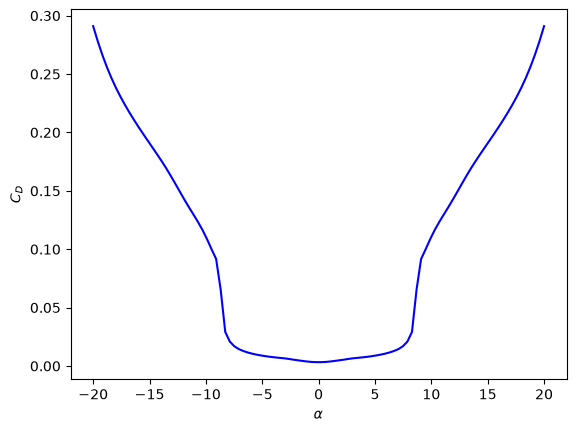

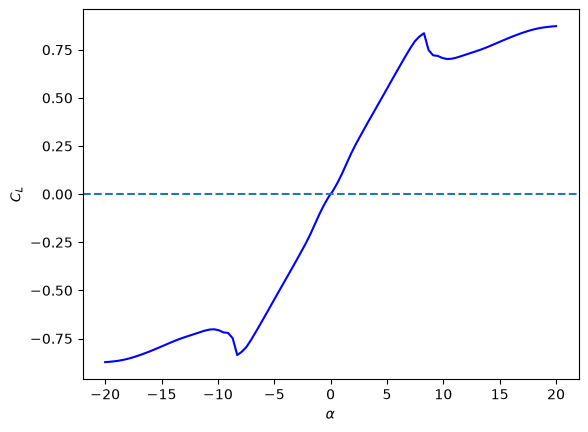

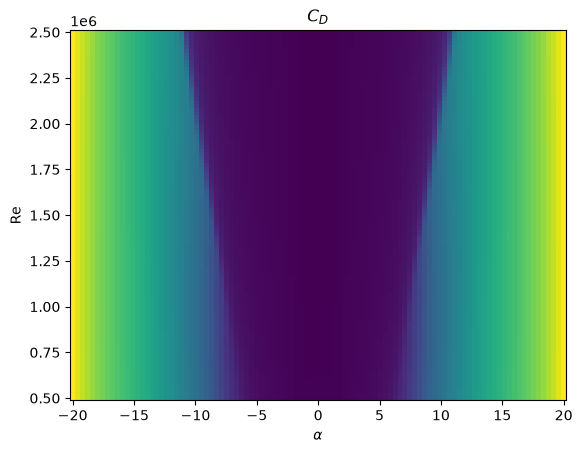

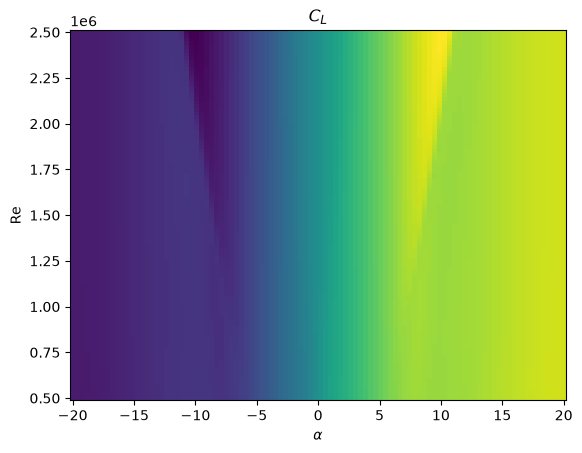

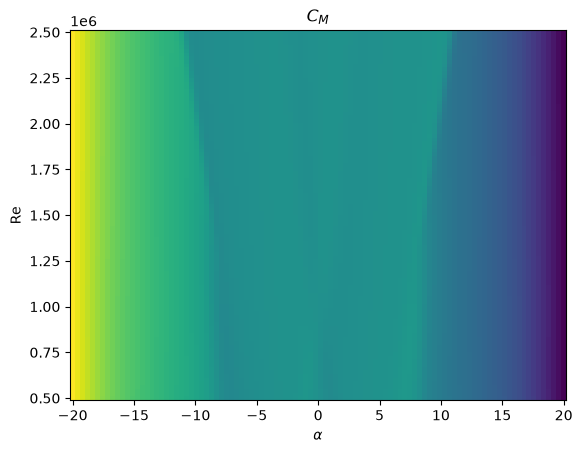

In [11]:
## aerodynamic polars: 
plt.plot(alpha_sweep["CD"], alpha_sweep["CL"], linestyle="-", label="(CD, CL)")
plt.xlabel("$C_D$")
plt.ylabel("$C_L$")
plt.title("Aerodynamic polar") 
plt.show()

## alpha and Re sweep plots 
## CD 
plt.plot(alphas, alpha_sweep["CD"], linestyle='-', color='blue') 
plt.xlabel("$\\alpha$")
plt.ylabel("$C_D$")
plt.show()

## CL 
plt.plot(alphas, alpha_sweep["CL"], linestyle='-', color='blue')
plt.axhline(y=0, linestyle="--")
plt.xlabel("$\\alpha$")
plt.ylabel("$C_L$")
plt.show() 

## Field plots
plt.pcolormesh(a_batch, re_batch, aero_fields["CD"].reshape(_grid_res, _grid_res))
plt.xlabel("$\\alpha$")
plt.ylabel("Re")
plt.title("$C_D$")
plt.show()

plt.pcolormesh(a_batch, re_batch, aero_fields["CL"].reshape(_grid_res, _grid_res))
plt.xlabel("$\\alpha$")
plt.ylabel("Re")
plt.title("$C_L$")
plt.show()

plt.pcolormesh(a_batch, re_batch, aero_fields["CM"].reshape(_grid_res, _grid_res))
plt.xlabel("$\\alpha$")
plt.title("$C_M$")
plt.ylabel("Re")
plt.show()

# Aerodynamic analysis 

The aerodynamic analysis of a NACA0006 airfoil exhibits a rather regular tendency across an operating condition domain. 

**Overall behavior** An overall tendency across fields is the relatively optimal conditions within an interval of angle around $0$. The drag optimised mostly at $\alpha = 0$ (next paragraph) is also relatively expectable and low within this angle interval. Similarly, lift coefficient varies linearly within this range, and displays an abrupt loss (in absolute value) at the boundary. While the shift is overall less drastic (visually) for the pitching moment coefficient $C_M$, a similar behavior is observed. Overall, the sharpness of the transition at this critical angle increases with the Reynolds number. 

**Drag** As seen on the angle sweep, and the aerodynamic polar, the drag is minimised at $\alpha = 0$ and a symmetric behavior is observed on either half-spaces $\alpha > 0, \alpha < 0$. 

# Analysis and perspectives 
Generating aeordynamic fields for a given airfoil is a straightforward thing to do (especially using cheap neuralfoil). The field display typical symmetry properties related to the choosen (symmetric) profile: 
- Symmetry with respect to $\alpha$ of the $C_D$
- Anti-symmetry with respect to $\alpha$ of the $C_L$.
- The $C_M$ seems to exhibit some kind of pseudo-symmetry around a negative angle

In general, the aerodynamic coefficients are invariant with respect to variation of speed (at the $Re$ variations we considered here) as the fields exhibit quite "horizontal lines". 

Computationally, neuralfoil allows an incredibly fast (relatively, compared to say, XFoil) method to generate the fields (next cells for CPU time analysis). However, seeing the tendencies of the fields (relatively smooth, and in some particular cases symmetric), it is realistic to imagine some interpolation method that works best for the reconstruction of those fields and hence reduce further the computational cost (also eventually imagine bypassing the need for neuralfoil entirely).  

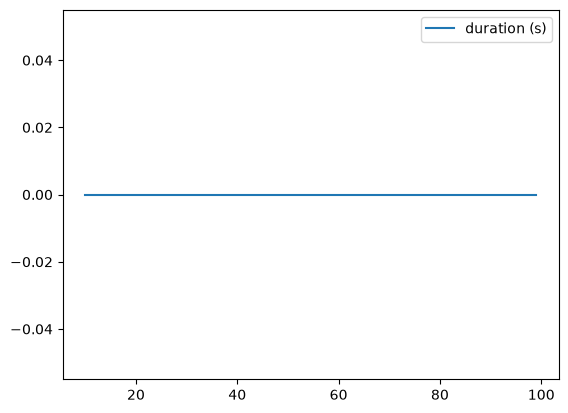

In [6]:
## Analyses the computational time of field generation 

from time import perf_counter as pc
res_levels = np.arange(10, 100) ## grid resolutions to consider 
durations = np.zeros_like(res_levels)

for i, _grid_res in enumerate(res_levels):
    start = pc()
    alpha = 0
    reynold = 2e6
    alphas = np.linspace(-5, 5, _grid_res)
    reynolds = np.linspace(reynold - 1e5, reynold + 1e5, _grid_res)
    
    ## for field 
    a_batch, re_batch = np.meshgrid(alphas, reynolds)
    
    ## different sweeps 
    alpha_sweep = airfoil.get_aero_from_neuralfoil(alpha=alphas, Re=reynold, model_size="xxxlarge")
    re_sweep = airfoil.get_aero_from_neuralfoil(alpha=alpha, Re=reynold, model_size='xxxlarge')

    durations[i] = pc() - start

## plot durations 
plt.plot(res_levels, durations, linestyle='-', label="duration (s)")
plt.legend()
plt.show()